# CTRL_FUT vs LCC_FUT: vegetation state and spin-up lineage

**Question.** D1/D2 found that ~99 % of the FUT ΔE(ISOP+MTERP) (LCC − CTRL) and a +0.25 W m⁻² tropical far field lie **outside** the land-cover-modified cells (`../other-BVOC-emission-magnitude/D1 D2 results interpretation and next checks.pdf`, §1 and §7 checks 1 + 3).
The suspected cause is that the two members start from **different land states**. This notebook checks that directly:

| Section | What | Output |
|---|---|---|
| 0 | Spin-up lineage of both members, read from the history files and `lnd_in` | `lineage.csv` |
| A | 2001–2009 regional means of TLAI, TOTVEGC, TOTECOSYSC, GPP; Δ, Welch p, drift | `A_nudged_regional_means.csv`, `A_nudged_timeseries.png` |
| B | Maps and zonal means of LCC_FUT − CTRL_FUT, with cell-wise significance | `B_*.csv/png` |
| C | Every stage of both lineages on one axis, "land years since the CMIP6 2100 state" | `C_*.csv/png` |

**Why it matters.** The surfdata differ only at 46–82°N (`PCT_NAT_PFT`). A vegetation difference in the tropics therefore cannot come from the land-cover change itself (b): it would point to spin-up history. If so, Total_FUT and O1's BGP term need CTRL_FUT rerun from a spin-up consistent with the LCC family.

**Lineage (a, from case scripts and `CaseDocs/lnd_in`; re-checked from files in §0):**

| Stage | Branch | Case | Run | fsurdat | Starts from |
|---|---|---|---|---|---|
| 0 | — | `NSSP585frc2_f19_tn14_20191014` | CMIP6 SSP5-8.5 | (CMIP6 transient) | — |
| `spinup` | shared | `…spinup_f19_f19-3` | 20 yr coupled, free | simyr2000 | NSSP585frc2 r.2100-01-01 |
| `CTRL_FUT` | CTRL | `…nudg_ctrl…-20260925` | nudged 2000–2009 | simyr2000 | spinup r.0021 |
| `landonly_LCC` | LCC | `I2100ssp585Clm50BgcCropCplHist…-20260924` | 100 yr land-only (cplhist of spinup yrs 11–20) | LPJ-GUESS | spinup r.0021 |
| `spinup_LCC` | LCC | `…spinup_lcc…-20260928` | 20 yr coupled, free | LPJ-GUESS | landonly r.0101 |
| `LCC_FUT` | LCC | `…nudg_lcc…-20261005` | nudged 2000–2009 | LPJ-GUESS | spinup_LCC r.0021 |

So CTRL_FUT's land has had **20 years** to adjust from the CMIP6 2100 state (with its own PFTs, climate and CO₂) to the simyr2000 surfdata; LCC_FUT's land has had **140 years**.

Evidence tags: **(a)** verified · **(b)** inference · **(c)** unverified. Run on Betzy in `lcc-env`. The first run reads ~400 history files from NIRD; annual means are cached in `equilibrium_outputs/CTRL_FUT_vs_LCC_FUT/`.

In [1]:
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from scipy import stats

ARCHIVE = Path('/nird/datapeak/NS9188K/adelez/BRL-FRST-XPSN_archive')
CASE_ROOT = Path('~/cases/BRL_FRST_XPSN').expanduser()
MASK_FILE = Path('lcc-modified-cells/modified_cells.nc')
OUT = Path('equilibrium_outputs/CTRL_FUT_vs_LCC_FUT')
OUT.mkdir(parents=True, exist_ok=True)
REBUILD_CACHE = False  # True re-reads the history files

# Land-state lineage, oldest first. handed_on = model years completed when the restart was written for the next stage.
STAGES = pd.DataFrame([
    ('spinup',       'shared', 'NF2100ssp585norbc_tropstratchem_spinup_f19_f19-3',            'coupled, free',      'simyr2000', 20),
    ('CTRL_FUT',     'CTRL',   'NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20260925',  'coupled, nudged',    'simyr2000', np.nan),
    ('landonly_LCC', 'LCC',    'I2100ssp585Clm50BgcCropCplHist_f19_f19-20260924',             'land-only, cplhist', 'LPJGUESS',  100),
    ('spinup_LCC',   'LCC',    'NF2100ssp585norbc_tropstratchem_spinup_lcc_f19_f19-20260928', 'coupled, free',      'LPJGUESS',  20),
    ('LCC_FUT',      'LCC',    'NF2100ssp585norbc_tropstratchem_nudg_lcc_f19_f19-20261005',   'coupled, nudged',    'LPJGUESS',  np.nan),
], columns=['stage', 'branch', 'case', 'kind', 'surfdata', 'handed_on']).set_index('stage')

VARS = ['TLAI', 'TOTVEGC', 'TOTECOSYSC', 'GPP']
NUDGED_YEARS = (2001, 2009)  # 2000 = 12 spin-up months, dropped
ALPHA = 0.05
COLOR = {'shared': '0.35', 'CTRL': '#1f77b4', 'LCC': '#d95f02'}

## 0. Lineage from the files

`Surface_dataset` and `case_id` come from the first `clm2.h0` file of each stage; `fsurdat`/`finidat` from `CaseDocs/lnd_in` (not available for the land-only case). With `use_init_interp = .true.` the file attribute `Initial_conditions_dataset` is only `finidat_interp_dest.nc`, so `finidat` must come from `lnd_in`.

In [2]:
def hist_files(case):
    files = sorted((ARCHIVE / case / 'lnd/hist').glob('*.clm2.h0.*.nc'))
    if not files:
        raise FileNotFoundError(f'No clm2.h0 files for {case}')
    return files

def open_hist(path):
    return xr.open_dataset(path, decode_times=xr.coders.CFDatetimeCoder(use_cftime=True))

def namelist_value(case, key):
    for root in (CASE_ROOT, CASE_ROOT / 'BRL_FRST_XPSN_archive'):
        lnd_in = root / case / 'CaseDocs/lnd_in'
        if lnd_in.is_file():
            match = re.search(rf"^\s*{key}\s*=\s*'([^']*)'", lnd_in.read_text(), re.M)
            return Path(match.group(1)).name if match else 'not set'
    return 'no lnd_in'

rows = []
for stage, s in STAGES.iterrows():
    files = hist_files(s.case)
    with open_hist(files[0]) as first, open_hist(files[-1]) as last:
        rows.append(dict(stage=stage, branch=s.branch, kind=s.kind, files=len(files),
                         first_bound=str(first.time_bounds.values[0, 0])[:16],
                         last_bound=str(last.time_bounds.values[-1, 1])[:16],
                         case_id=first.attrs.get('case_id'), Surface_dataset=first.attrs.get('Surface_dataset'),
                         fsurdat=namelist_value(s.case, 'fsurdat'), finidat=namelist_value(s.case, 'finidat')))
lineage = pd.DataFrame(rows).set_index('stage')
lineage.to_csv(OUT / 'lineage.csv')
display(lineage)

for stage, s in STAGES.iterrows():
    found = lineage.loc[stage, 'Surface_dataset']
    assert s.surfdata in found, f'{stage}: expected {s.surfdata} surfdata, file says {found}'
    if lineage.loc[stage, 'case_id'] != s.case:
        print(f"⚠ {stage}: file case_id = {lineage.loc[stage, 'case_id']!r}, archive folder = {s.case!r}")

,branch,kind,files,first_bound,last_bound,case_id,Surface_dataset,fsurdat,finidat
stage,,,,,,,,,
spinup,shared,"coupled, free",20,0000-12-31 23:30,0021-01-01 00:00,NF2100ssp585norbc_tropstratchem_spinup_f19_f19-3,surfdata_1.9x2.5_hist_78pfts_CMIP6_simyr2000_c...,surfdata_1.9x2.5_hist_78pfts_CMIP6_simyr2000_c...,NSSP585frc2_f19_tn14_20191014.clm2.r.2100-01-0...
CTRL_FUT,CTRL,"coupled, nudged",120,1999-12-31 23:30,2010-01-01 00:00,NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_...,surfdata_1.9x2.5_hist_78pfts_CMIP6_simyr2000_c...,surfdata_1.9x2.5_hist_78pfts_CMIP6_simyr2000_c...,NF2100ssp585norbc_tropstratchem_spinup_f19_f19...
landonly_LCC,LCC,"land-only, cplhist",11,0000-12-31 23:30,0101-01-01 00:00,I2100ssp585Clm50BgcCropCplHist_f19_f19-test-20...,surfdata_1.9x2.5_SSP5-8.5_2100_78pfts_LPJGUESS.nc,no lnd_in,no lnd_in
spinup_LCC,LCC,"coupled, free",240,0000-12-31 23:30,0021-01-01 00:00,NF2100ssp585norbc_tropstratchem_spinup_lcc_f19...,surfdata_1.9x2.5_SSP5-8.5_2100_78pfts_LPJGUESS.nc,surfdata_1.9x2.5_SSP5-8.5_2100_78pfts_LPJGUESS.nc,I2100ssp585Clm50BgcCropCplHist_f19_f19-2026092...
LCC_FUT,LCC,"coupled, nudged",120,1999-12-31 23:30,2010-01-01 00:00,NF2100ssp585norbc_tropstratchem_nudg_lcc_f19_f...,surfdata_1.9x2.5_SSP5-8.5_2100_78pfts_LPJGUESS.nc,surfdata_1.9x2.5_SSP5-8.5_2100_78pfts_LPJGUESS.nc,NF2100ssp585norbc_tropstratchem_spinup_lcc_f19...


⚠ landonly_LCC: file case_id = 'I2100ssp585Clm50BgcCropCplHist_f19_f19-test-20260924', archive folder = 'I2100ssp585Clm50BgcCropCplHist_f19_f19-20260924'


## Annual means and data checks

Annual means are weighted by the length of each `time_bounds` interval. Each interval goes to the year of its **midpoint**. The bounds start 30 min before the nominal start date, so taking the start would put January in the previous year. Years without 365 days of coverage are dropped. This removes, for example, the zero-length record at t = 0 in the land-only output.
Spatial weights are `area × landfrac`. Cell values are the grid-cell means as CLM writes them (b: over the landunits CLM averages each field on).

In [3]:
def annual_means(case):
    parts = []
    for f in hist_files(case):
        with open_hist(f) as ds:
            bounds = ds.time_bounds.values
            days = np.array([(end - start).total_seconds() / 86400 for start, end in bounds])
            years = np.array([(start + (end - start) / 2).year for start, end in bounds])
            calendar = bounds[0, 0].calendar
            parts.append(ds[VARS].load().assign_coords(year=('time', years), days=('time', days)))
            grid = ds[['area', 'landfrac']].load()
    ds = xr.concat(parts, 'time')
    if pd.Index(ds.time.values).duplicated().any():
        raise ValueError(f'{case}: duplicated time steps')
    covered = ds.days.groupby('year').sum()
    ann = (ds[VARS] * ds.days).groupby('year').sum(min_count=1) / covered
    ann = ann.sel(year=covered.year[np.abs(covered - 365) < 0.5])
    for v in VARS:
        ann[v].attrs = ds[v].attrs
    ann = ann.assign(area=grid.area, landfrac=grid.landfrac)
    ann.attrs.update(case=case, calendar=calendar,
                     method='clm2.h0 -> annual mean weighted by time_bounds length, interval assigned to its midpoint year; years with <365 d dropped')
    return ann

def load_stage(stage):
    path = OUT / f'annual_{stage}.nc'
    if path.is_file() and not REBUILD_CACHE:
        return xr.open_dataset(path).load()
    ann = annual_means(STAGES.loc[stage, 'case'])
    ann.to_netcdf(path)
    return ann

ANN = {stage: load_stage(stage) for stage in STAGES.index}

ref = ANN['CTRL_FUT']
checks = pd.DataFrame([dict(
    stage=stage, years=f'{int(a.year[0])}–{int(a.year[-1])}', n_years=a.sizes['year'],
    same_grid=np.array_equal(a.lat, ref.lat) and np.array_equal(a.lon, ref.lon),
    same_area=bool(np.allclose(a.area, ref.area, equal_nan=True)),
    same_landfrac=bool(np.allclose(a.landfrac, ref.landfrac, equal_nan=True)),
    units=', '.join(a[v].attrs.get('units', '?') for v in VARS), calendar=a.attrs['calendar'])
    for stage, a in ANN.items()]).set_index('stage')
display(checks)
assert checks[['same_grid', 'same_area', 'same_landfrac']].all().all(), 'grids differ: do not compare'
assert checks.units.nunique() == 1 and (checks.calendar == 'noleap').all()

,years,n_years,same_grid,same_area,same_landfrac,units,calendar
stage,,,,,,,
spinup,1–20,20,True,True,True,"m^2/m^2, gC/m^2, gC/m^2, gC/m^2/s",noleap
CTRL_FUT,2000–2009,10,True,True,True,"m^2/m^2, gC/m^2, gC/m^2, gC/m^2/s",noleap
landonly_LCC,1–100,100,True,True,True,"m^2/m^2, gC/m^2, gC/m^2, gC/m^2/s",noleap
spinup_LCC,1–20,20,True,True,True,"m^2/m^2, gC/m^2, gC/m^2, gC/m^2/s",noleap
LCC_FUT,2000–2009,10,True,True,True,"m^2/m^2, gC/m^2, gC/m^2, gC/m^2/s",noleap


In [4]:
mask = xr.open_dataset(MASK_FILE).modified.astype(bool)
assert np.allclose(mask.lat, ref.lat) and np.allclose(mask.lon, ref.lon), 'mask grid differs'
mask = mask.assign_coords(lat=ref.lat, lon=ref.lon)
LAND = ref.landfrac > 0
LAT = ref.lat.broadcast_like(LAND)
REGIONS = {
    'global land': LAND,
    'tropics 30S-30N': LAND & (abs(LAT) <= 30),
    'NH >30N unmodified': LAND & (LAT > 30) & ~mask,
    'all unmodified land': LAND & ~mask,
    'modified cells': LAND & mask,
}
W = ref.area * ref.landfrac
SCALE = {'GPP': (86400 * 365, 'gC/m^2/yr')}

def scaled(ann, v):
    factor, units = SCALE.get(v, (1, ann[v].attrs.get('units', '?')))
    return ann[v] * factor, units

def regional_mean(field, region):
    w = W.where(REGIONS[region] & np.isfinite(field))
    return (field * w).sum(('lat', 'lon')) / w.sum(('lat', 'lon'))

def slope_per_decade(series):
    return 10 * np.polyfit(series.year.values.astype(float), series.values, 1)[0]

print({r: int(m.sum()) for r, m in REGIONS.items()}, '(land cells per region)')

{'global land': 5701, 'tropics 30S-30N': 1514, 'NH >30N unmodified': 1292, 'all unmodified land': 4549, 'modified cells': 1152} (land cells per region)


## A. Nudged runs, 2001–2009

Regional means for each year, then the 9-year mean, Δ = LCC_FUT − CTRL_FUT, Welch p on the 9 annual values, CTRL interannual SD, and each run's OLS drift (per decade, descriptive).
Nudging makes the two members share their weather, so the annual values are paired and autocorrelated; Welch p is only a rough guide (b).

In [5]:
y0, y1 = NUDGED_YEARS
NUD = {k: ANN[k].sel(year=slice(y0, y1)) for k in ('CTRL_FUT', 'LCC_FUT')}
assert all(n.sizes['year'] == y1 - y0 + 1 for n in NUD.values())

rows, SERIES = [], {}
for region in REGIONS:
    for v in VARS:
        (c, units), (l, _) = scaled(NUD['CTRL_FUT'], v), scaled(NUD['LCC_FUT'], v)
        c, l = regional_mean(c, region), regional_mean(l, region)
        SERIES[region, v] = c, l
        rows.append(dict(region=region, variable=v, units=units,
                         CTRL_FUT=float(c.mean()), LCC_FUT=float(l.mean()), delta=float(l.mean() - c.mean()),
                         delta_pct=float(100 * (l.mean() - c.mean()) / c.mean()),
                         p_welch=stats.ttest_ind(l.values, c.values, equal_var=False).pvalue,
                         ctrl_iav_sd=float(c.std(ddof=1)),
                         ctrl_drift_per_decade=slope_per_decade(c), lcc_drift_per_decade=slope_per_decade(l)))
table_A = pd.DataFrame(rows).set_index(['region', 'variable'])
table_A.to_csv(OUT / 'A_nudged_regional_means.csv')
display(table_A.round(3))

units   CTRL_FUT    LCC_FUT     delta  \
region              variable                                                
global land         TLAI          m^2/m^2      2.530      2.137    -0.394   
                    TOTVEGC        gC/m^2   6066.886   4248.550 -1818.336   
                    TOTECOSYSC     gC/m^2  24947.132  21433.880 -3513.252   
                    GPP         gC/m^2/yr   1170.227   1051.564  -118.664   
tropics 30S-30N     TLAI          m^2/m^2      3.366      2.806    -0.560   
                    TOTVEGC        gC/m^2   9124.909   6053.828 -3071.080   
                    TOTECOSYSC     gC/m^2  16436.619  11968.152 -4468.467   
                    GPP         gC/m^2/yr   1652.728   1470.549  -182.179   
NH >30N unmodified  TLAI          m^2/m^2      2.061      1.730    -0.331   
                    TOTVEGC        gC/m^2   3212.540   2035.731 -1176.809   
                    TOTECOSYSC     gC/m^2  15660.142  13137.728 -2522.414   
                    GPP         gC/m^2/yr    899.193    811.219   -87.973   
all unmodified land TLAI          m^2/m^2      2.562      2.145    -0.416   
                    TOTVEGC        gC/m^2   6049.984   4012.816 -2037.168   
                    TOTECOSYSC     gC/m^2  15578.017  12312.825 -3265.192   
                    GPP         gC/m^2/yr   1214.606   1086.246  -128.360   
modified cells      TLAI          m^2/m^2      2.370      2.093    -0.277   
                    TOTVEGC        gC/m^2   6153.634   5458.431  -695.203   
                    TOTECOSYSC     gC/m^2  73033.219  68246.824 -4786.394   
                    GPP         gC/m^2/yr    942.459    873.558   -68.901   

                                delta_pct  p_welch  ctrl_iav_sd  \
region              variable                                      
global land         TLAI          -15.557      0.0        0.015   
                    TOTVEGC       -29.971      0.0       68.945   
                    TOTECOSYSC    -14.083      0.0       87.092   
                    GPP           -10.140      0.0        8.199   
tropics 30S-30N     TLAI          -16.633      0.0        0.020   
                    TOTVEGC       -33.656      0.0      109.232   
                    TOTECOSYSC    -27.186      0.0      146.733   
                    GPP           -11.023      0.0        8.919   
NH >30N unmodified  TLAI          -16.042      0.0        0.028   
                    TOTVEGC       -36.632      0.0       35.640   
                    TOTECOSYSC    -16.107      0.0       54.736   
                    GPP            -9.784      0.0       15.005   
all unmodified land TLAI          -16.253      0.0        0.016   
                    TOTVEGC       -33.672      0.0       71.388   
                    TOTECOSYSC    -20.960      0.0       97.512   
                    GPP           -10.568      0.0        8.251   
modified cells      TLAI          -11.694      0.0        0.015   
                    TOTVEGC       -11.297      0.0       56.471   
                    TOTECOSYSC     -6.554      0.0       33.694   
                    GPP            -7.311      0.0       21.657   

                                ctrl_drift_per_decade  lcc_drift_per_decade  
region              variable                                                 
global land         TLAI                       -0.015                 0.030  
                    TOTVEGC                   251.083               433.297  
                    TOTECOSYSC                317.838               592.207  
                    GPP                         0.596                 6.663  
tropics 30S-30N     TLAI                       -0.054                 0.039  
                    TOTVEGC                   398.145               699.701  
                    TOTECOSYSC                535.386               928.695  
                    GPP                       -11.030                 3.408  
NH >30N unmodified  TLAI                        0.009                 0.010  
        

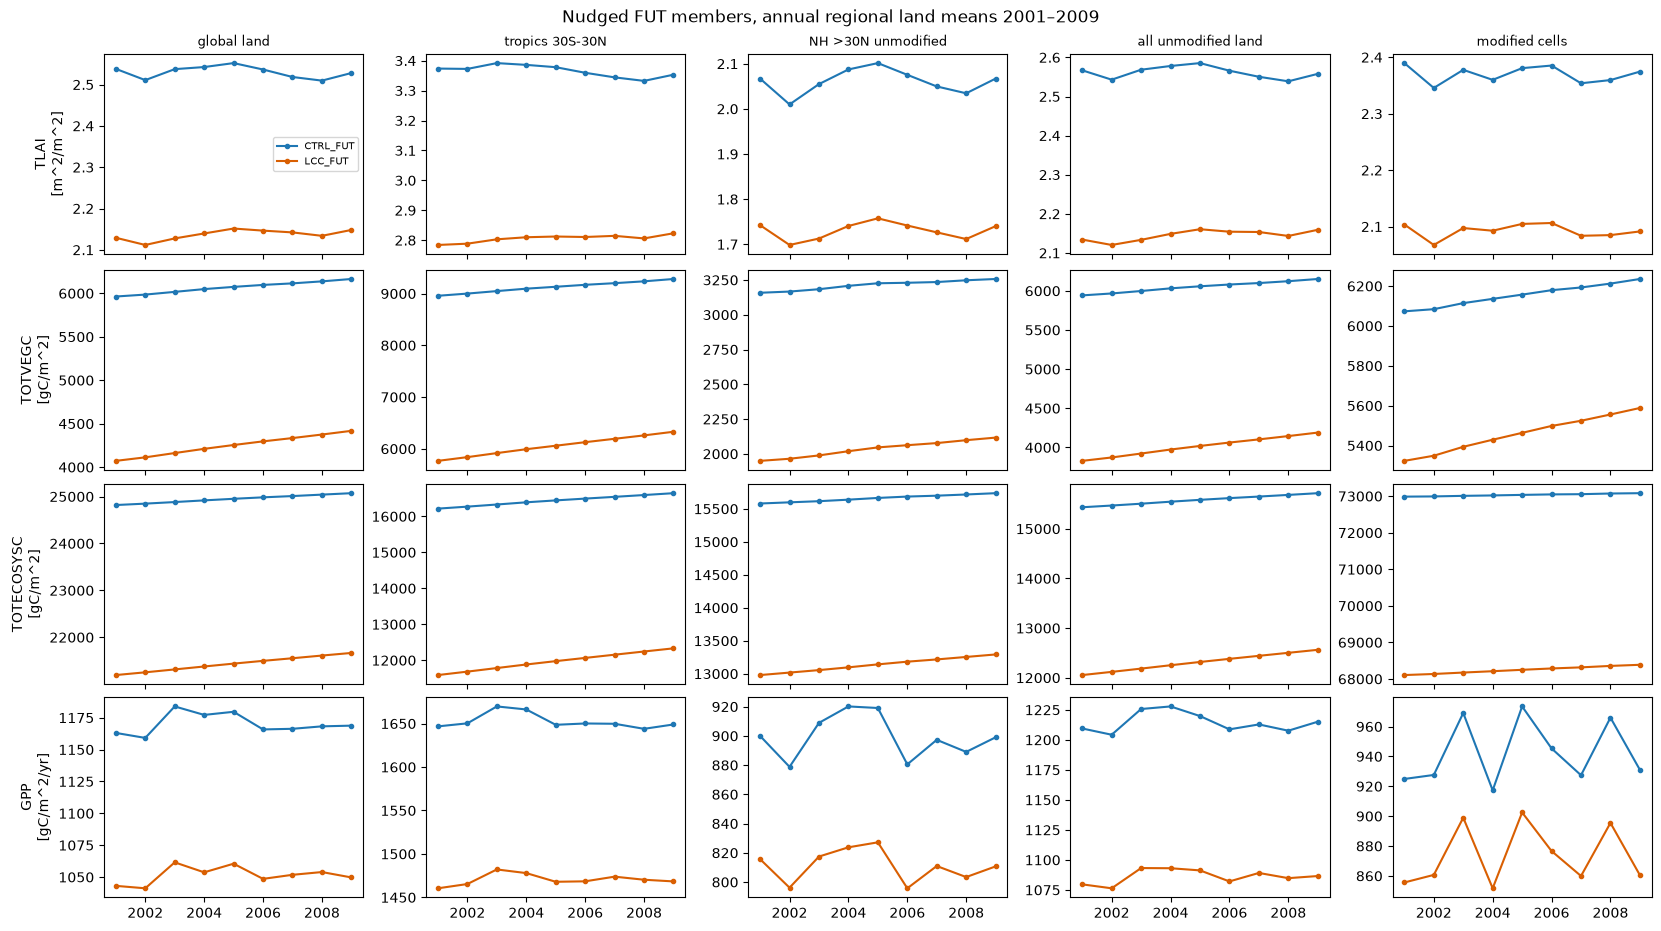

In [6]:
fig, axes = plt.subplots(len(VARS), len(REGIONS), figsize=(3.3 * len(REGIONS), 2.3 * len(VARS)),
                         sharex=True, layout='constrained')
for j, region in enumerate(REGIONS):
    for i, v in enumerate(VARS):
        ax = axes[i, j]
        c, l = SERIES[region, v]
        ax.plot(c.year, c, 'o-', ms=3, color=COLOR['CTRL'], label='CTRL_FUT')
        ax.plot(l.year, l, 'o-', ms=3, color=COLOR['LCC'], label='LCC_FUT')
        ax.set_title(region if i == 0 else '', fontsize=9)
        if j == 0:
            ax.set_ylabel(f"{v}\n[{table_A.loc[(region, v), 'units']}]")
axes[0, 0].legend(fontsize=7)
fig.suptitle(f'Nudged FUT members, annual regional land means {y0}–{y1}')
fig.savefig(OUT / 'A_nudged_timeseries.png', dpi=150)
plt.show()

## B. Where do the members differ? Maps and zonal means, 2001–2009

Δ of the 9-year means; TOTVEGC and GPP as % of CTRL (cells with small CTRL values are masked). Dots: cell-wise Welch p < 0.05 on the 9 annual values. With no real difference, about 5 % of the area would be dotted by chance. Magenta contour: modified cells.
The table gives the area-weighted mean Δ and the share of land area with p < 0.05 for each region.

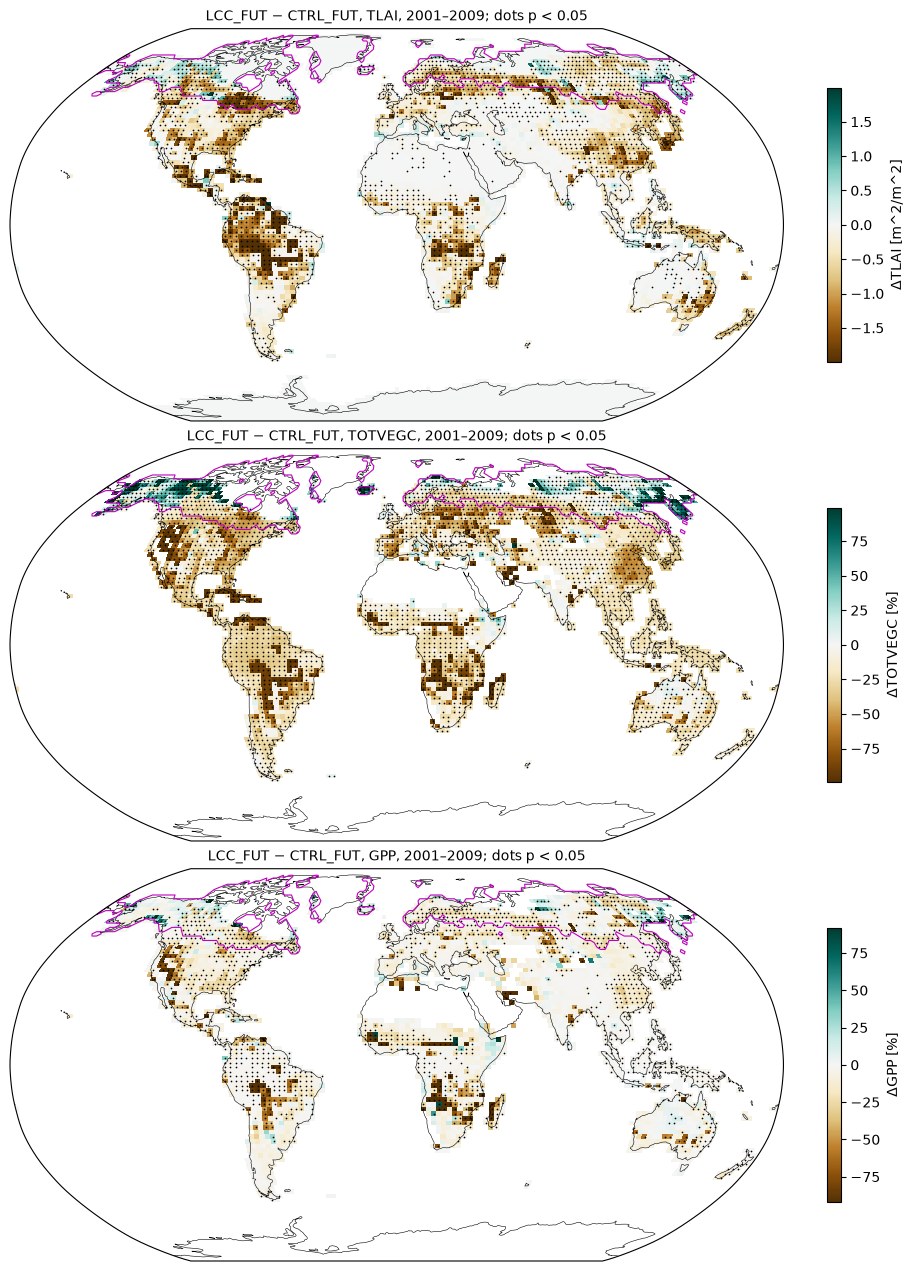

units  mean_delta  sig_area_frac  \
variable region                                                    
TLAI     global land          m^2/m^2      -0.394          0.520   
         tropics 30S-30N      m^2/m^2      -0.560          0.573   
         NH >30N unmodified   m^2/m^2      -0.331          0.547   
         all unmodified land  m^2/m^2      -0.416          0.495   
         modified cells       m^2/m^2      -0.277          0.649   
TOTVEGC  global land                %     -24.220          0.884   
         tropics 30S-30N            %     -30.960          0.855   
         NH >30N unmodified         %     -32.365          0.891   
         all unmodified land        %     -30.860          0.868   
         modified cells             %       9.033          0.964   
GPP      global land                %     -10.598          0.485   
         tropics 30S-30N            %     -12.289          0.520   
         NH >30N unmodified         %     -11.155          0.409   
         all unmodified land        %     -11.617          0.463   
         modified cells             %      -5.337          0.600   

                              sig_positive_frac  
variable region                                  
TLAI     global land                      0.050  
         tropics 30S-30N                  0.037  
         NH >30N unmodified               0.018  
         all unmodified land              0.026  
         modified cells                   0.171  
TOTVEGC  global land                      0.086  
         tropics 30S-30N                  0.023  
         NH >30N unmodified               0.028  
         all unmodified land              0.025  
         modified cells                   0.395  
GPP      global land                      0.045  
         tropics 30S-30N                  0.046  
         NH >30N unmodified               0.009  
         all unmodified land              0.031  
         modified cells                   0.120

In [7]:
MAPS = [('TLAI', 'abs'), ('TOTVEGC', 'pct'), ('GPP', 'pct')]
MIN_BASE = {'TOTVEGC': 100.0, 'GPP': 30.0}  # gC/m^2 and gC/m^2/yr: below this, % is not shown
c_ann, l_ann = NUD['CTRL_FUT'], NUD['LCC_FUT']

def delta_map(v, kind):
    c, units = scaled(c_ann, v)
    l, _ = scaled(l_ann, v)
    cm = c.mean('year')
    d = l.mean('year') - cm
    if kind == 'pct':
        d, units = 100 * d / cm.where(cm > MIN_BASE[v]), '%'
    with warnings.catch_warnings(), np.errstate(all='ignore'):
        warnings.simplefilter('ignore')
        p = stats.ttest_ind(l.values, c.values, axis=0, equal_var=False).pvalue
    return d.where(LAND), xr.DataArray(p, coords=cm.coords), units

rows = []
fig, axes = plt.subplots(len(MAPS), 1, figsize=(10, 4.2 * len(MAPS)),
                         subplot_kw=dict(projection=ccrs.Robinson()), layout='constrained')
for ax, (v, kind) in zip(axes, MAPS):
    d, p, units = delta_map(v, kind)
    lim = float(np.nanpercentile(abs(d), 98))
    m = ax.pcolormesh(d.lon, d.lat, d, transform=ccrs.PlateCarree(), cmap='BrBG',
                      vmin=-lim, vmax=lim, shading='nearest')
    sig = ((p < ALPHA) & np.isfinite(d)).values
    yy, xx = np.meshgrid(d.lat, d.lon, indexing='ij')
    ax.scatter(xx[sig], yy[sig], s=1.5, c='k', lw=0, transform=ccrs.PlateCarree())
    ax.contour(mask.lon, mask.lat, mask.astype(int), levels=[0.5], colors='m', linewidths=0.8,
               transform=ccrs.PlateCarree())
    ax.coastlines(lw=0.4)
    ax.set_global()
    fig.colorbar(m, ax=ax, shrink=0.7, label=f'Δ{v} [{units}]')
    ax.set_title(f'LCC_FUT − CTRL_FUT, {v}, {y0}–{y1}; dots p < {ALPHA}', fontsize=10)
    for region in REGIONS:
        w = W.where(REGIONS[region] & np.isfinite(d))
        rows.append(dict(variable=v, units=units, region=region,
                         mean_delta=float((d * w).sum() / w.sum()),
                         sig_area_frac=float(w.where(p < ALPHA).sum() / w.sum()),
                         sig_positive_frac=float(w.where((p < ALPHA) & (d > 0)).sum() / w.sum())))
fig.savefig(OUT / 'B_delta_maps.png', dpi=150)
plt.show()

table_B = pd.DataFrame(rows).set_index(['variable', 'region'])
table_B.to_csv(OUT / 'B_delta_area_stats.csv')
display(table_B.round(3))

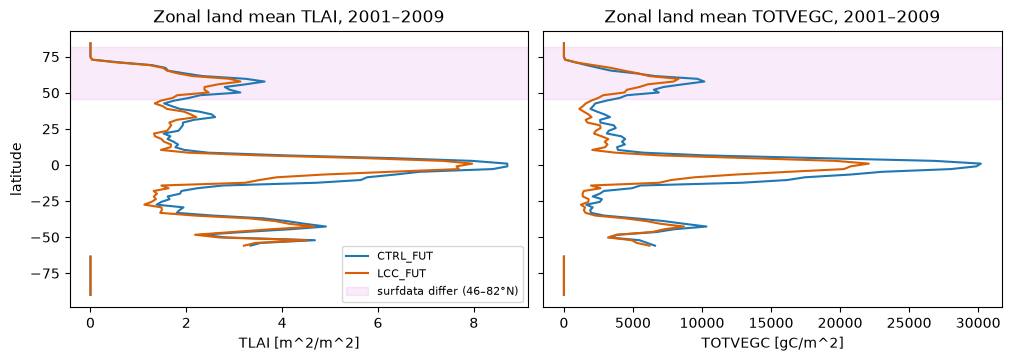

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True, layout='constrained')
for ax, v in zip(axes, ['TLAI', 'TOTVEGC']):
    for name, ann in NUD.items():
        f, units = scaled(ann, v)
        f = f.mean('year')
        w = W.where(LAND & np.isfinite(f))
        ax.plot((f * w).sum('lon') / w.sum('lon'), f.lat, color=COLOR[name.split('_')[0]], label=name)
    ax.axhspan(46, 82, color='m', alpha=0.08, label='surfdata differ (46–82°N)')
    ax.set(xlabel=f'{v} [{units}]', title=f'Zonal land mean {v}, {y0}–{y1}')
axes[0].set_ylabel('latitude')
axes[0].legend(fontsize=8)
fig.savefig(OUT / 'B_zonal_means.png', dpi=150)
plt.show()

## C. Lineage: every stage on one axis

x = land years since the CMIP6 2100 state. Shared `spinup` 1–20, then CTRL branch: CTRL_FUT 21–30. LCC branch: land-only 21–120 → `spinup_LCC` 121–140 → LCC_FUT 141–150.
Only the years handed on to the next stage are plotted. Jumps at stage boundaries can come from a change in forcing (datm cplhist vs coupled; free vs nudged; surfdata switch) and are **not** drift (b). Look at the trend *within* a stage.
The table gives the OLS trend over the last 10 years of each stage, in % per decade of that stage's mean.

{'spinup': (1, 20), 'CTRL_FUT': (21, 30), 'landonly_LCC': (21, 120), 'spinup_LCC': (121, 140), 'LCC_FUT': (141, 150)}


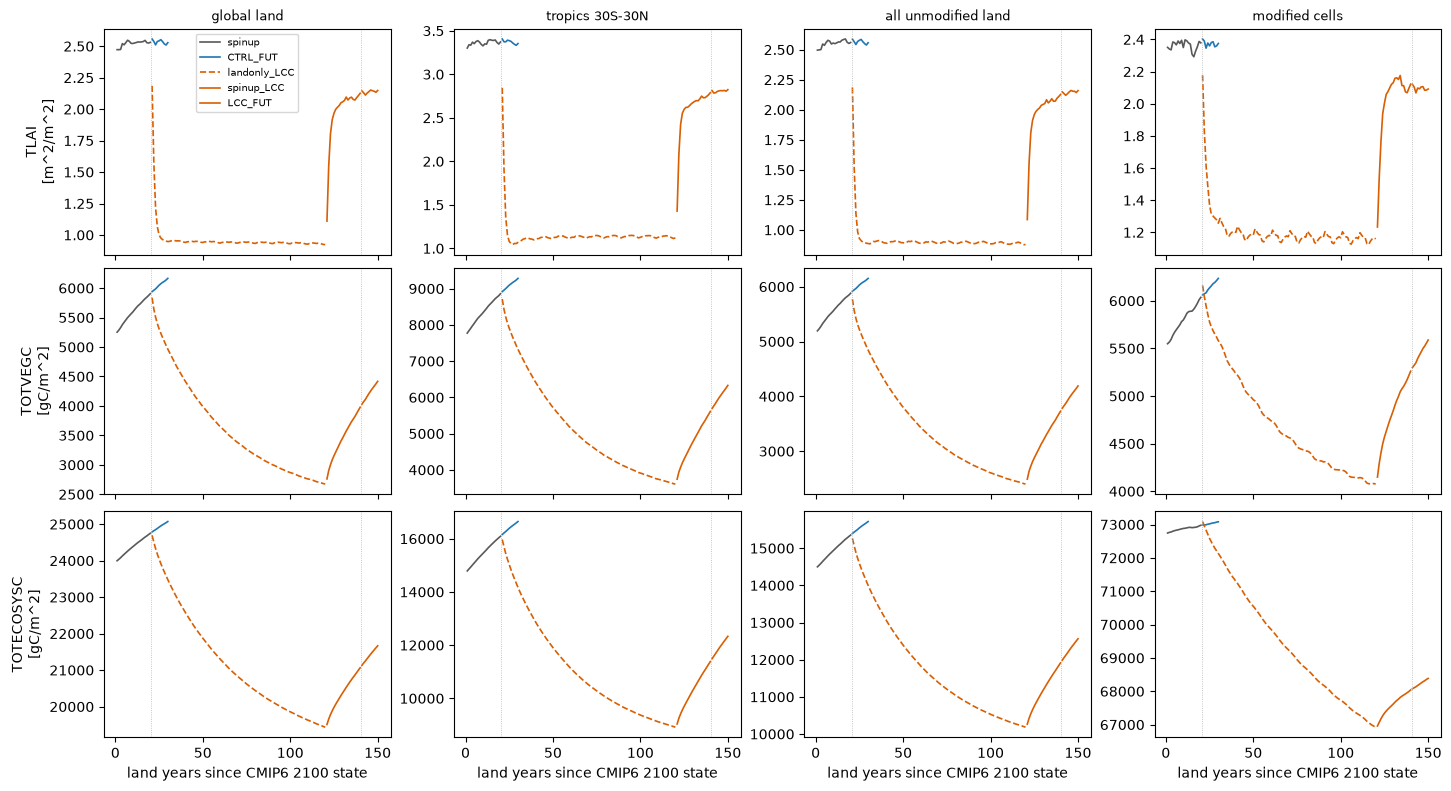

stage                           spinup  CTRL_FUT  landonly_LCC  spinup_LCC  \
variable   region                                                            
TLAI       all unmodified land    0.29     -1.01         -0.72        3.03   
           global land            0.07     -1.01         -1.18        1.82   
           modified cells        -1.20     -0.97         -2.96       -4.28   
           tropics 30S-30N        0.15     -1.81         -1.95        3.68   
TOTECOSYSC all unmodified land    2.76      2.30         -1.52        6.31   
           global land            1.48      1.28         -1.01        3.26   
           modified cells         0.11      0.16         -0.61        0.58   
           tropics 30S-30N        4.04      3.31         -2.30        9.85   
TOTVEGC    all unmodified land    5.52      4.34         -3.81       15.23   
           global land            5.18      4.16         -3.37       13.51   
           modified cells         3.52      3.27         -2.02        7.47   
           tropics 30S-30N        5.89      4.43         -3.80       15.85   

stage                           LCC_FUT  
variable   region                        
TLAI       all unmodified land     1.12  
           global land             0.82  
           modified cells         -0.79  
           tropics 30S-30N         0.90  
TOTECOSYSC all unmodified land     5.23  
           global land             2.78  
           modified cells          0.52  
           tropics 30S-30N         7.86  
TOTVEGC    all unmodified land    11.39  
           global land            10.27  
           modified cells          6.08  
           tropics 30S-30N        11.70

In [9]:
AXIS, end_of = {}, {'shared': 0}
for stage, s in STAGES.iterrows():
    ann = ANN[stage]
    start = 0 if s.branch == 'shared' else end_of.get(s.branch, end_of['shared'])
    n = ann.year - int(ann.year[0]) + 1
    if pd.notna(s.handed_on):
        assert int(n.max()) >= s.handed_on, f'{stage}: only {int(n.max())} complete years, {s.handed_on} handed on'
        ann = ANN[stage] = ann.sel(year=ann.year[n <= s.handed_on])
        n = n[n <= s.handed_on]
        end_of[s.branch] = start + int(s.handed_on)
    AXIS[stage] = start + n.values
print({k: (int(v[0]), int(v[-1])) for k, v in AXIS.items()})

C_REGIONS = ['global land', 'tropics 30S-30N', 'all unmodified land', 'modified cells']
C_VARS = ['TLAI', 'TOTVEGC', 'TOTECOSYSC']
rows = []
fig, axes = plt.subplots(len(C_VARS), len(C_REGIONS), figsize=(3.6 * len(C_REGIONS), 2.6 * len(C_VARS)),
                         sharex=True, layout='constrained')
for j, region in enumerate(C_REGIONS):
    for i, v in enumerate(C_VARS):
        ax = axes[i, j]
        for stage, s in STAGES.iterrows():
            field, units = scaled(ANN[stage], v)
            series = regional_mean(field, region)
            ax.plot(AXIS[stage], series, color=COLOR[s.branch], lw=1.2,
                    ls='--' if 'land-only' in s.kind else '-', label=stage)
            last = series.isel(year=slice(-10, None))
            rows.append(dict(variable=v, region=region, stage=stage,
                             trend_pct_per_decade=100 * slope_per_decade(last) / float(last.mean())))
        for x in sorted(set(end_of.values()) - {0}):
            ax.axvline(x + 0.5, color='0.7', lw=0.6, ls=':')
        ax.set_title(region if i == 0 else '', fontsize=9)
        if j == 0:
            ax.set_ylabel(f'{v}\n[{units}]')
axes[0, 0].legend(fontsize=7)
for ax in axes[-1]:
    ax.set_xlabel('land years since CMIP6 2100 state')
fig.savefig(OUT / 'C_lineage_timeseries.png', dpi=150)
plt.show()

table_C = pd.DataFrame(rows).pivot_table(index=['variable', 'region'], columns='stage',
                                         values='trend_pct_per_decade')[list(STAGES.index)]
table_C.to_csv(OUT / 'C_last10yr_trend_pct_per_decade.csv')
display(table_C.round(2))

## Summary (run 2026-10-22, outputs in `equilibrium_outputs/CTRL_FUT_vs_LCC_FUT/`)

👉 **The FUT members are in very different vegetation states everywhere, not only where the surfdata differ. LCC_FUT has much *less* vegetation. Neither member is in equilibrium.** The likely cause is the CO₂ used in the FUT land-only spin-up.

**1. Lineage (a, §0).** Confirmed from the files: CTRL_FUT has 20 land years since the CMIP6 2100 state, LCC_FUT has 140. The land-only output's `case_id` is `I2100…-test-20260924` (a); the meaning of that label is unverified (c).

**2. Δ = LCC_FUT − CTRL_FUT, 2001–2009 (a, tables A/B):**

| Region | ΔTLAI | ΔTOTVEGC | ΔTOTECOSYSC | ΔGPP |
|---|---|---|---|---|
| all unmodified land | −0.42 m² m⁻² (−16 %) | −34 % | −21 % | −11 % |
| tropics 30°S–30°N | −0.56 m² m⁻² (−17 %) | −34 % | −27 % | −11 % |
| NH >30°N, unmodified | −0.33 m² m⁻² (−16 %) | −37 % | −16 % | −10 % |
| modified cells | −0.28 m² m⁻² (−12 %) | −11 % | −7 % | −7 % |

(% = difference of regional means.) On unmodified land, cells with p < 0.05 cover 50 % of the area for TLAI and 87 % for TOTVEGC, against ~5 % expected by chance. Almost all of them are negative. The tropical ΔTLAI is ~28× CTRL's interannual SD (0.020).
This fits D2's −250 Tg yr⁻¹ global ΔE(ISOP+MTERP) in FUT (b): less leaf area gives less emission.

**3. Drift (a, table C, last-10-yr OLS, TOTVEGC, tropics):**

| Stage | Trend |
|---|---|
| spinup | +5.9 %/decade |
| CTRL_FUT | +4.4 %/decade |
| landonly_LCC | −3.8 %/decade |
| spinup_LCC | +15.9 %/decade |
| LCC_FUT | +11.7 %/decade |

Vegetation carbon fell during the 100-yr land-only stage and is regrowing fast in the coupled stages. Both members are still drifting, LCC_FUT about 2.5× faster.

**4. Likely cause (setting (a), link (b)).** The FUT land-only case `I2100ssp585Clm50BgcCropCplHist_f19_f19-20260924` has `CLM_CO2_TYPE = constant` and `CCSM_CO2_PPMV = 284.32`. CLM therefore saw **pre-industrial CO₂ for 100 years**. The coupled runs use `co2_type = diagnostic`, i.e. the atmospheric SSP5-8.5 2100 CO₂ (~1100 ppm, value not checked here (c)). Neither `22b` nor `12b` sets CO₂. The PD land-only case got `367.0` ppm, which is consistent with 2000 (a).
Losing CO₂ fertilisation for 100 years would explain a global vegetation loss that the following 20 coupled years have not recovered (b).
Supporting evidence:
- **Shape:** global TLAI falls from ≈2.5 to ≈0.95 m² m⁻² within ~5 years of the land-only stage and then stays flat (figure C) (a).
- **PD control:** the PD land-only run (`I2000…-20260925`, correct 367 ppm) shows no collapse. Annual global TLAI stays at ≈1.4 throughout and TOTVEGC rises from 3600 to 3970 gC m⁻² over 100 yr (a, checked by hand, not in this notebook).
- **What remains open:** this points to CO₂ rather than a generic land-only or cplhist problem (b), but a FUT-specific cplhist forcing issue is not excluded (c).

**5. Implications (b):**
- **Total_FUT** (D1/D2) is dominated by this state difference. It cannot be read as a land-cover effect.
- **Rerunning only CTRL_FUT from the LCC lineage would not fix it**, because the LCC lineage itself carries the low-CO₂ spin-up. A consistent fix is to redo the FUT land-only spin-up with 2100 CO₂, for the CTRL and LCC surfdata alike, then the coupled spin-ups. That needs the user's decision.
- **BVOC_FUT** pairs share the LCC state, so the spin-up mismatch largely cancels there. But they still describe emissions from a vegetation state that is too low and still regrowing.
- **PD** is not checked here. Its land-only CO₂ was correct, but the extra 100-yr spin-up still separates LCC_PD from CTRL_PD (CLAUDE.md: tropical TOTVEGC +10 %).